In [33]:
import numpy as np
import torch
import torch.nn as nn
from scripts.data import load_lfw, make_splits, TripletDataset, IMG_SIZE
from scripts.model import EmbeddingNet, EMBEDDING_DIM
from torch.utils.data import DataLoader
from tqdm import tqdm
import time
import matplotlib.pyplot as plt

In [28]:
SEED = 42
MODELS_DIR = "./models"

batch_size = 48
lr = 3e-4
margin = 0.3
epochs = 10

In [3]:
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
device

device(type='cuda')

In [7]:
images, labels, class_names = load_lfw()
train_idx, val_idx, _ = make_splits(labels)

In [10]:
train_ds = TripletDataset(images[train_idx], labels[train_idx], train=True)
val_ds = TripletDataset(images[val_idx], labels[val_idx], train=False)
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=batch_size)

In [14]:
model = EmbeddingNet().to(device)
criterion = nn.TripletMarginLoss(margin=margin)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

In [16]:
sum(p.numel() for p in model.parameters())

11242176

In [26]:
IMG_SIZE, EMBEDDING_DIM

(112, 128)

In [30]:
history = {"train_loss": [], "val_loss": []}
best_val = float("inf")
ckpt_path = MODELS_DIR + "/" + "triplet.pt"

for epoch in tqdm(range(1, epochs + 1), desc="train triplet"):
    t0 = time.time()
    model.train()
    tr_loss, seen = 0.0, 0
    for a, p, n in train_dl:
        a, p, n = a.to(device), p.to(device), n.to(device)
        loss = criterion(model(a), model(p), model(n))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(a)
        seen += len(a)
    tr_loss /= seen 

    model.eval()
    va_loss, seen = 0.0, 0
    with torch.no_grad():
        for a, p, n in val_dl:
            a, p, n = a.to(device), p.to(device), n.to(device)
            va_loss += criterion(model(a), model(p), model(n)).item() * len(a)
            seen += len(a)
    va_loss /= seen
    scheduler.step()  

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    print(f"epoch {epoch:02d} | train {tr_loss:.4f} | val {va_loss:.4f} "
          f"| {time.time()-t0:.0f}s") 

    if va_loss < best_val:
        best_val = va_loss
        torch.save({
            "model_type": "triplet",
            "state_dict": model.state_dict(),
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "embedding_dim": EMBEDDING_DIM,
            "val_loss": va_loss,
        }, ckpt_path)

train triplet:  10%|████████▎                                                                          | 1/10 [00:21<03:11, 21.26s/it]

epoch 01 | train 0.0021 | val 0.0648 | 21s


train triplet:  20%|████████████████▌                                                                  | 2/10 [00:44<03:01, 22.69s/it]

epoch 02 | train 0.0019 | val 0.0690 | 24s


train triplet:  30%|████████████████████████▉                                                          | 3/10 [01:04<02:27, 21.07s/it]

...

epoch 08 | train 0.0041 | val 0.1407 | 22s


train triplet:  90%|██████████████████████████████████████████████████████████████████████████▋        | 9/10 [03:16<00:21, 21.48s/it]

epoch 09 | train 0.0078 | val 0.1238 | 20s


train triplet: 100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [03:37<00:00, 21.72s/it]

epoch 10 | train 0.0208 | val 0.1838 | 21s


In [31]:
best_val

0.05401875651040614

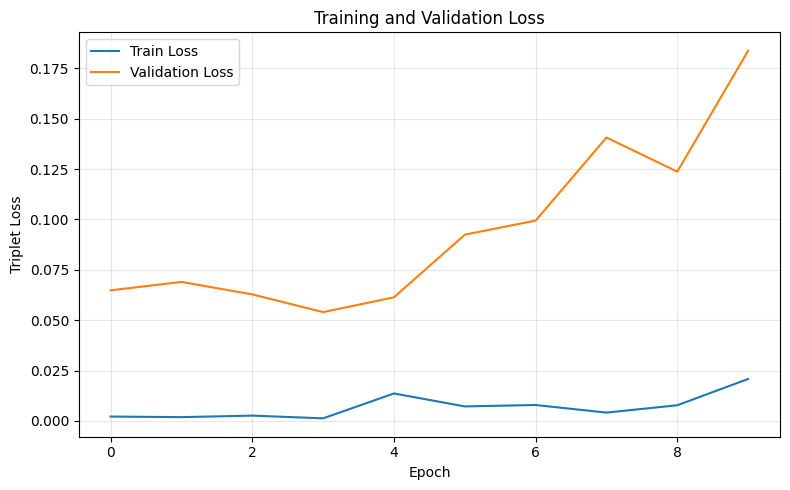

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Triplet Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()